

> # Real Estate Investment Advisor: Predicting Property Profitability & Future Value
**Exploratory Data Analysis (EDA), Machine Learning (Classification & Regression), MLflow & Streamlit Deployment**

## 1. Project Description & Business Context
Imagine an investor with a budget of 50 Lakhs looking to purchase a property—such as a 4BHK flat in Noida—who needs to know whether the listing is a sound investment and how much the property will appreciate over the next 3 to 5 years. Real estate valuation depends on foundational features (State, City, Locality, Property Type, BHK, Size in SqFt, and Asking Price) alongside critical livability and infrastructure factors:
* **Connectivity:** Proximity to metro stations, bus stops, or airports (ideally within a 1.5 to 2 km radius).
* **Essential Civic & Social Infrastructure:** Reliable water and drainage connections, nearby schools, hospitals, daily grocery markets, and entertainment hubs (shopping malls and cinemas).
* **Property Amenities:** Furnishing status, gated society security, and dedicated parking space.

**Objectives:**
1. **Classification Model:** Evaluate property features and local market medians to classify whether a listing is a **Good Investment** (`1` = Yes, `0` = No).
2. **Regression Model:** Forecast the estimated property valuation after **3 Years** and **5 Years** based on compound annual appreciation and infrastructure scores.
3. **Experiment Tracking & Deployment:** Log models with MLflow and deploy an interactive Streamlit web application for real-time investor recommendations.


In [13]:
# 1. Import core libraries for data manipulation and numerical operations
import pandas as pd
import numpy as np

# 2. Import visualization libraries for Exploratory Data Analysis (EDA)
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Import Machine Learning & Preprocessing tools from Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    mean_squared_error, mean_absolute_error, r2_score
)

# 4. Import MLflow for experiment tracking
import mlflow
import mlflow.sklearn

# Suppress warnings for clean notebook output formatting
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!




> ## 2. Data Loading, Initial Exploration & Data Dictionary
We load the real estate dataset containing **250,000 property records** across **23 features** (`2 float64`, `9 int64`, and `12 object` columns). We inspect the raw structure using four standard exploration commands:
* `df.head()`: Displays the first 5 rows to verify column headers and initial records.
* `df.tail()`: Displays the last 5 rows to confirm the file loaded completely without corruption at the end.
* `df.info()`: Prints column names, non-null counts, and exact data types.
* `df.describe()`: Summarizes key descriptive statistics (count, mean, standard deviation, min, quartiles, and max) for numerical columns.

### Complete Data Dictionary
| Column | Feature Name | Data Type | Description |
| :--- | :--- | :--- | :--- |
| 0 | ID | int64 | Unique identifier for each property record |
| 1 | State | object | State where the property is located |
| 2 | City | object | City where the property is located |
| 3 | Locality | object | Specific neighborhood or locality |
| 4 | Property_Type | object | Type of property (Apartment, Independent House, Villa) |
| 5 | BHK | int64 | Number of Bedrooms, Hall, and Kitchen (ranges from 1 to 5, mean 3.00) |
| 6 | Size_in_SqFt | int64 | Area of the property in square feet (500 to 5,000 SqFt, mean 2,749.81) |
| 7 | Price_in_Lakhs | float64 | Current price of the property in Lakhs (10.00 to 500.00, mean 254.59) |
| 8 | Price_per_SqFt | float64 | Normalized price per square foot in Lakhs (mean 0.13, median 0.09) |
| 9 | Year_Built | int64 | Year when the property was constructed (1990 to 2023) |
| 10 | Furnished_Status | object | Furnishing level (Furnished, Semi-Furnished, Unfurnished) |
| 11 | Floor_No | int64 | Floor number of the property (0 to 30) |
| 12 | Total_Floors | int64 | Total number of floors in the building (1 to 30) |
| 13 | Age_of_Property | int64 | Age of the property in years (2 to 35 years, mean 18.48) |
| 14 | Nearby_Schools | int64 | Number of nearby schools (1 to 10, mean 5.50) |
| 15 | Nearby_Hospitals | int64 | Number of nearby hospitals (1 to 10, mean 5.50) |
| 16 | Public_Transport_Accessibility | object | Access to metro/bus/train within 1.5-2 km (High, Medium, Low) |
| 17 | Parking_Space | object | Dedicated parking availability (Yes, No) |
| 18 | Security | object | Gated society security features like CCTV/Guard (Yes, No) |
| 19 | Amenities | object | Available lifestyle amenities (Gym, Pool, Clubhouse, Garden, Playground) |
| 20 | Facing | object | Direction the property faces (North, South, East, West) |
| 21 | Owner_Type | object | Listing ownership type (Owner, Builder, Broker) |
| 22 | Availability_Status | object | Current status (Ready_to_Move, Under_Construction) |


In [14]:
# Load the dataset into a Pandas DataFrame
df = pd.read_csv('india_housing_prices.csv')

def explore_dataset(dataframe):
    """
    Executes standard exploratory data commands (head, tail, info, describe)
    to verify data structure, types, and statistical summaries.
    """
    print("--- 1. FIRST 5 ROWS (HEAD) ---")
    display(dataframe.head())

    print("\n--- 2. LAST 5 ROWS (TAIL) ---")
    display(dataframe.tail())

    print("\n--- 3. DATASET INFORMATION & DATA TYPES (INFO) ---")
    dataframe.info()

    print("\n--- 4. STATISTICAL SUMMARY OF NUMERICAL FEATURES (DESCRIBE) ---")
    display(dataframe.describe().round(2))

# Execute the modular exploration function
explore_dataset(df)

--- 1. FIRST 5 ROWS (HEAD) ---


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move



--- 2. LAST 5 ROWS (TAIL) ---


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
249995,249996,Gujarat,Ahmedabad,Locality_187,Independent House,5,1995,274.75,0.14,1995,...,30,8,6,Low,No,No,"Playground, Garden, Gym, Clubhouse, Pool",East,Broker,Under_Construction
249996,249997,Tamil Nadu,Chennai,Locality_348,Apartment,1,2293,13.40,0.01,2013,...,12,8,10,Low,No,No,Playground,South,Broker,Ready_to_Move
249997,249998,Telangana,Warangal,Locality_225,Villa,4,2910,236.94,0.08,2003,...,22,10,4,High,Yes,Yes,Playground,South,Builder,Under_Construction
249998,249999,Odisha,Cuttack,Locality_138,Villa,1,1149,141.66,0.12,2007,...,18,3,7,Low,Yes,Yes,"Playground, Gym, Pool",South,Owner,Ready_to_Move
249999,250000,Haryana,Gurgaon,Locality_268,Independent House,3,4313,199.69,0.05,1990,...,35,10,6,Medium,No,No,"Gym, Garden",South,Owner,Under_Construction



--- 3. DATASET INFORMATION & DATA TYPES (INFO) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  object 
 2   City                            250000 non-null  object 
 3   Locality                        250000 non-null  object 
 4   Property_Type                   250000 non-null  object 
 5   BHK                             250000 non-null  int64  
 6   Size_in_SqFt                    250000 non-null  int64  
 7   Price_in_Lakhs                  250000 non-null  float64
 8   Price_per_SqFt                  250000 non-null  float64
 9   Year_Built                      250000 non-null  int64  
 10  Furnished_Status                250000 non-null  object 
 11  Floor_No                  

,ID,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals
count,250000.00,250000.00,250000.00,250000.00,250000.00,250000.00,250000.00,250000.00,250000.00,250000.00,250000.00
mean,125000.50,3.00,2749.81,254.59,0.13,2006.52,14.97,15.50,18.48,5.50,5.50
std,72168.93,1.42,1300.61,141.35,0.13,9.81,8.95,8.67,9.81,2.88,2.87
min,1.00,1.00,500.00,10.00,0.00,1990.00,0.00,1.00,2.00,1.00,1.00
25%,62500.75,2.00,1623.00,132.55,0.05,1998.00,7.00,8.00,10.00,3.00,3.00
50%,125000.50,3.00,2747.00,253.87,0.09,2007.00,15.00,15.00,18.00,5.00,5.00
75%,187500.25,4.00,3874.00,376.88,0.16,2015.00,23.00,23.00,27.00,8.00,8.00
max,250000.00,5.00,5000.00,500.00,0.99,2023.00,30.00,30.00,35.00,10.00,10.00




> ## 3. Looking for Missing/Duplicate Values & Feature Engineering
Before visualizing trends or training models, we clean the dataset and engineer domain-specific investment features:
1. **Missing & Duplicate Values Check:** Inspect the dataset via `.isnull().sum()` and `.duplicated().sum()`. Both return **0**, confirming the dataset is clean without requiring row deletion or statistical imputation.
2. **Feature Engineering:**
   * `School_Density_Score`: Combines `Nearby_Schools` and `Nearby_Hospitals` as a proxy for essential neighborhood infrastructure (schools, healthcare, daily groceries, and civic utilities).
   * `Future_Price_3Y` & `Future_Price_SY` (5 Years): Regression target variables projecting property value after 3 years and 5 years at an 8% compound annual growth rate ($Future = Current \times (1 + 0.08)^t$). For example, a 50 Lakh property appreciates to **62.99 Lakhs** in 3 years and **73.47 Lakhs** in 5 years.
   * `Good_Investment`: Binary classification target (`1` if `Price_in_Lakhs` is less than or equal to the city's median property price, else `0`).


In [15]:
def preprocess_and_engineer_data(dataframe):
    """
    Checks for missing values and duplicates, engineers infrastructure and
    future price target variables, and creates an encoded copy for ML modeling.
    """
    # 1. Check for missing (NaN/Null) values per column
    print("--- MISSING VALUES COUNT PER COLUMN ---")
    missing_counts = dataframe.isnull().sum()
    print(missing_counts)
    print(f"\nTotal missing values: {missing_counts.sum()}")

    # 2. Check for duplicate rows
    duplicate_count = dataframe.duplicated().sum()
    print(f"Total duplicate rows: {duplicate_count}")
    if duplicate_count > 0:
        dataframe.drop_duplicates(inplace=True)

    # 3. Engineer new domain features
    # Infrastructure score combining nearby schools and healthcare access
    dataframe['School_Density_Score'] = dataframe['Nearby_Schools'] + dataframe['Nearby_Hospitals']

    # Regression Targets: 3-Year and 5-Year Future Price at 8% annual appreciation
    annual_growth_rate = 0.08
    dataframe['Future_Price_3Y'] = (dataframe['Price_in_Lakhs'] * ((1 + annual_growth_rate) ** 3)).round(2)
    dataframe['Future_Price_SY'] = (dataframe['Price_in_Lakhs'] * ((1 + annual_growth_rate) ** 5)).round(2)

    # Classification Target: Good Investment (1 if Price <= City Median Price, else 0)
    median_price_per_city = dataframe.groupby('City')['Price_in_Lakhs'].transform('median')
    dataframe['Good_Investment'] = (dataframe['Price_in_Lakhs'] <= median_price_per_city).astype(int)

    print("\n--- ENGINEERED FEATURES PREVIEW ---")
    display(dataframe[['City', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Future_Price_3Y', 'Future_Price_SY', 'Good_Investment']].head())
    return dataframe

# Execute preprocessing while keeping readable text labels for EDA charts
df = preprocess_and_engineer_data(df)

--- MISSING VALUES COUNT PER COLUMN ---
ID                                0
State                             0
City                              0
Locality                          0
Property_Type                     0
BHK                               0
Size_in_SqFt                      0
Price_in_Lakhs                    0
Price_per_SqFt                    0
Year_Built                        0
Furnished_Status                  0
Floor_No                          0
Total_Floors                      0
Age_of_Property                   0
Nearby_Schools                    0
Nearby_Hospitals                  0
Public_Transport_Accessibility    0
Parking_Space                     0
Security                          0
Amenities                         0
Facing                            0
Owner_Type                        0
Availability_Status               0
dtype: int64

Total missing values: 0
Total duplicate rows: 0

--- ENGINEERED FEATURES PREVIEW ---


,City,BHK,Size_in_SqFt,Price_in_Lakhs,Future_Price_3Y,Future_Price_SY,Good_Investment
0,Chennai,1,4740,489.76,616.96,719.62,0
1,Pune,3,2364,195.52,246.30,287.28,1
2,Ludhiana,2,3642,183.79,231.52,270.05,1
3,Jodhpur,2,2741,300.29,378.28,441.22,0
4,Jaipur,4,4823,182.90,230.40,268.74,1




> ## 4. Exploratory Data Analysis (EDA) — 5 Distinct Visualizations
We generate **five different visualization types** to uncover regional price distributions, property size relationships, and connectivity impacts:
1. **Visualization 1 (Correlation Heatmap):** Displays Pearson correlation coefficients across numerical features. `Price_in_Lakhs` has a perfect **1.00** correlation with `Future_Price_3Y` and `Future_Price_SY`, a **0.56** positive correlation with `Price_per_SqFt`, and a strong **-0.87** negative correlation with `Good_Investment` (confirming lower-priced properties relative to the median are classified as stronger investments). `Size_in_SqFt` and `Price_per_SqFt` show a **-0.61** correlation.
2. **Visualization 2 (Histogram with KDE):** Illustrates the overall distribution of property prices across the market (spanning 10 Lakhs to 500 Lakhs, with a mean of 254.59 Lakhs and standard deviation of 141.35 Lakhs).
3. **Visualization 3 (Bar Chart):** Compares the average asking price of a **3BHK flat** across the top 10 cities (led by Bangalore, Dehradun, Nagpur, Mysore, Pune, Kochi, and Noida).
4. **Visualization 4 (Box Plot):** Evaluates `Price_per_SqFt` across different `Property_Type` categories (`Apartment`, `Independent House`, `Villa`) grouped by `Public_Transport_Accessibility` (`High`, `Medium`, `Low`), highlighting median values and upper-end luxury outliers.
5. **Visualization 5 (Scatter Plot):** Maps `Size_in_SqFt` against `Price_in_Lakhs`, color-coded by `Good_Investment` status (`1` vs `0`), clearly showing the price threshold separating good investments from overpriced listings.


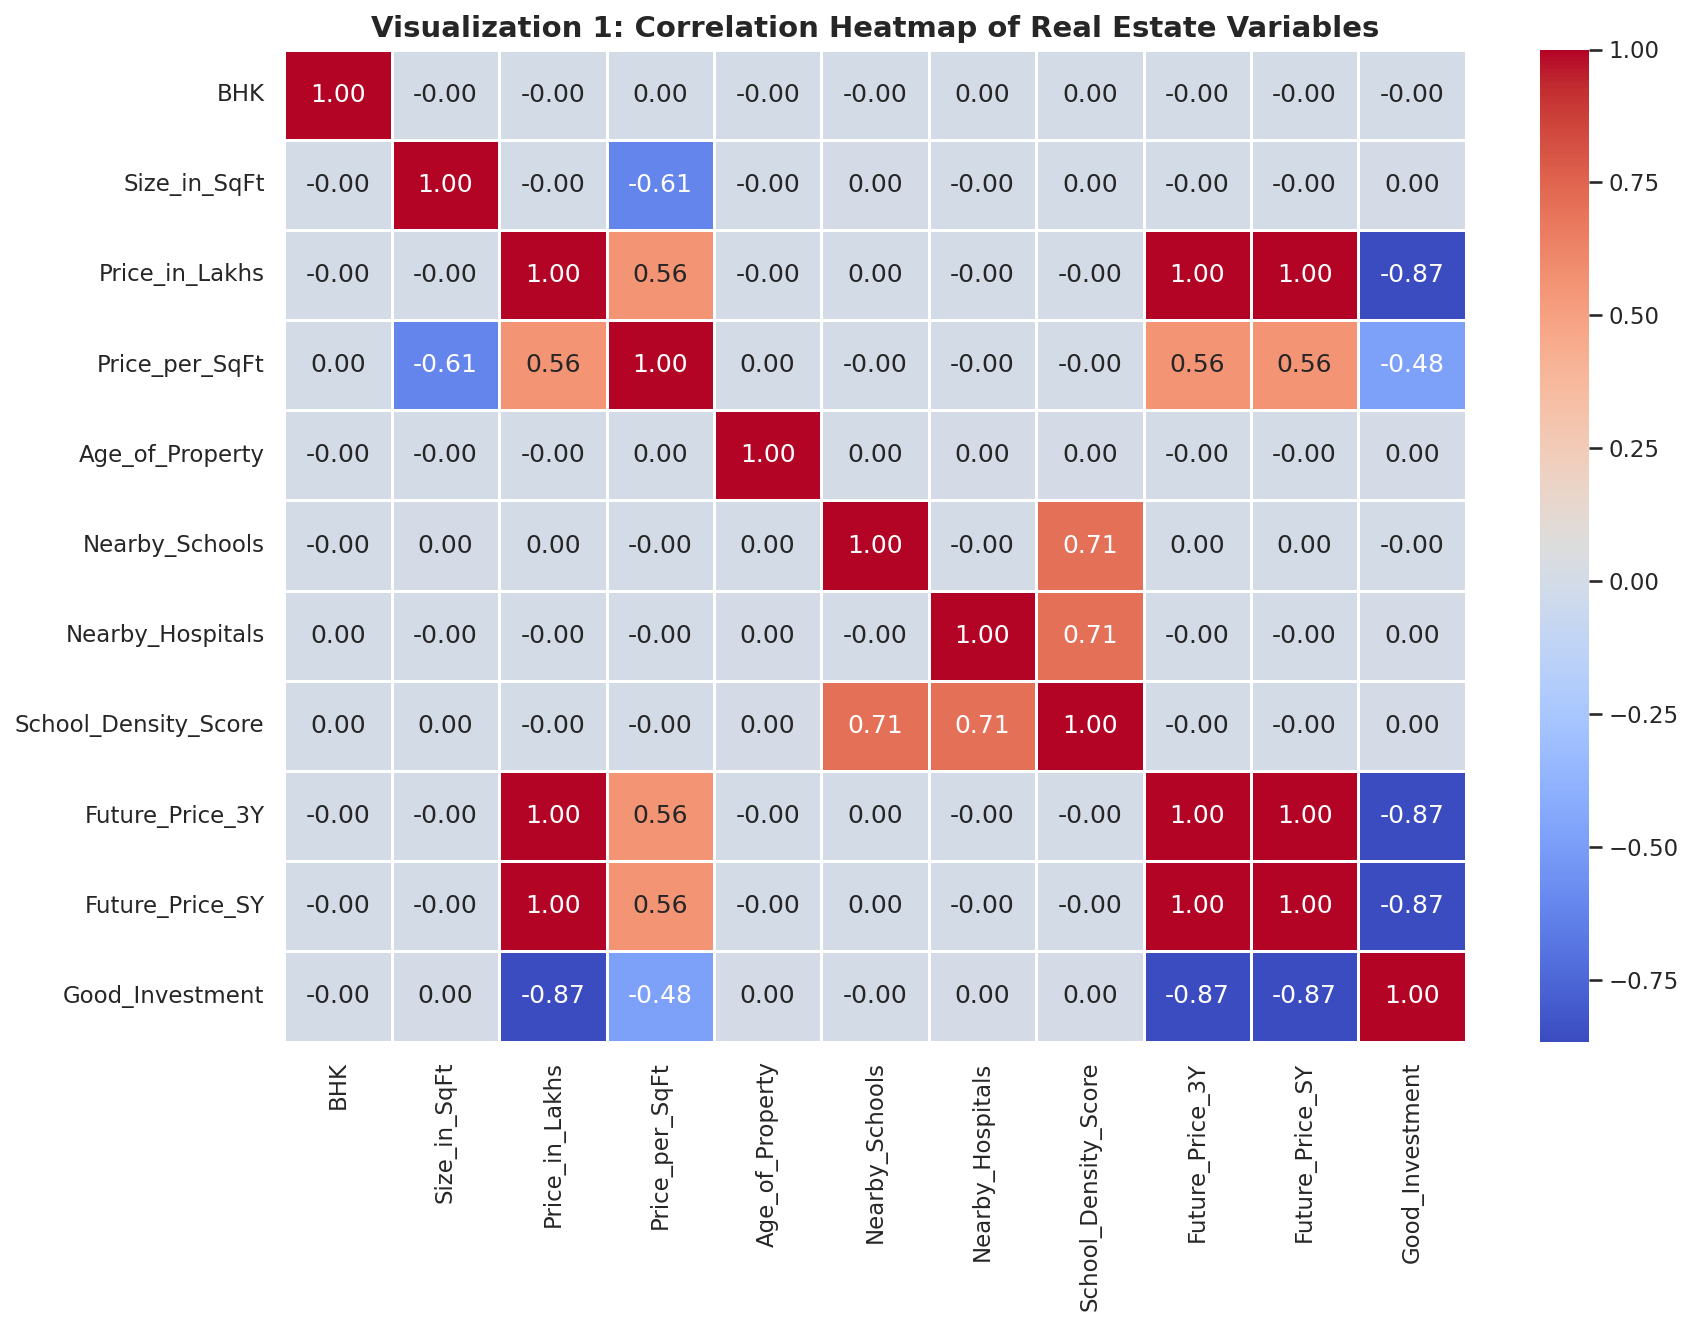

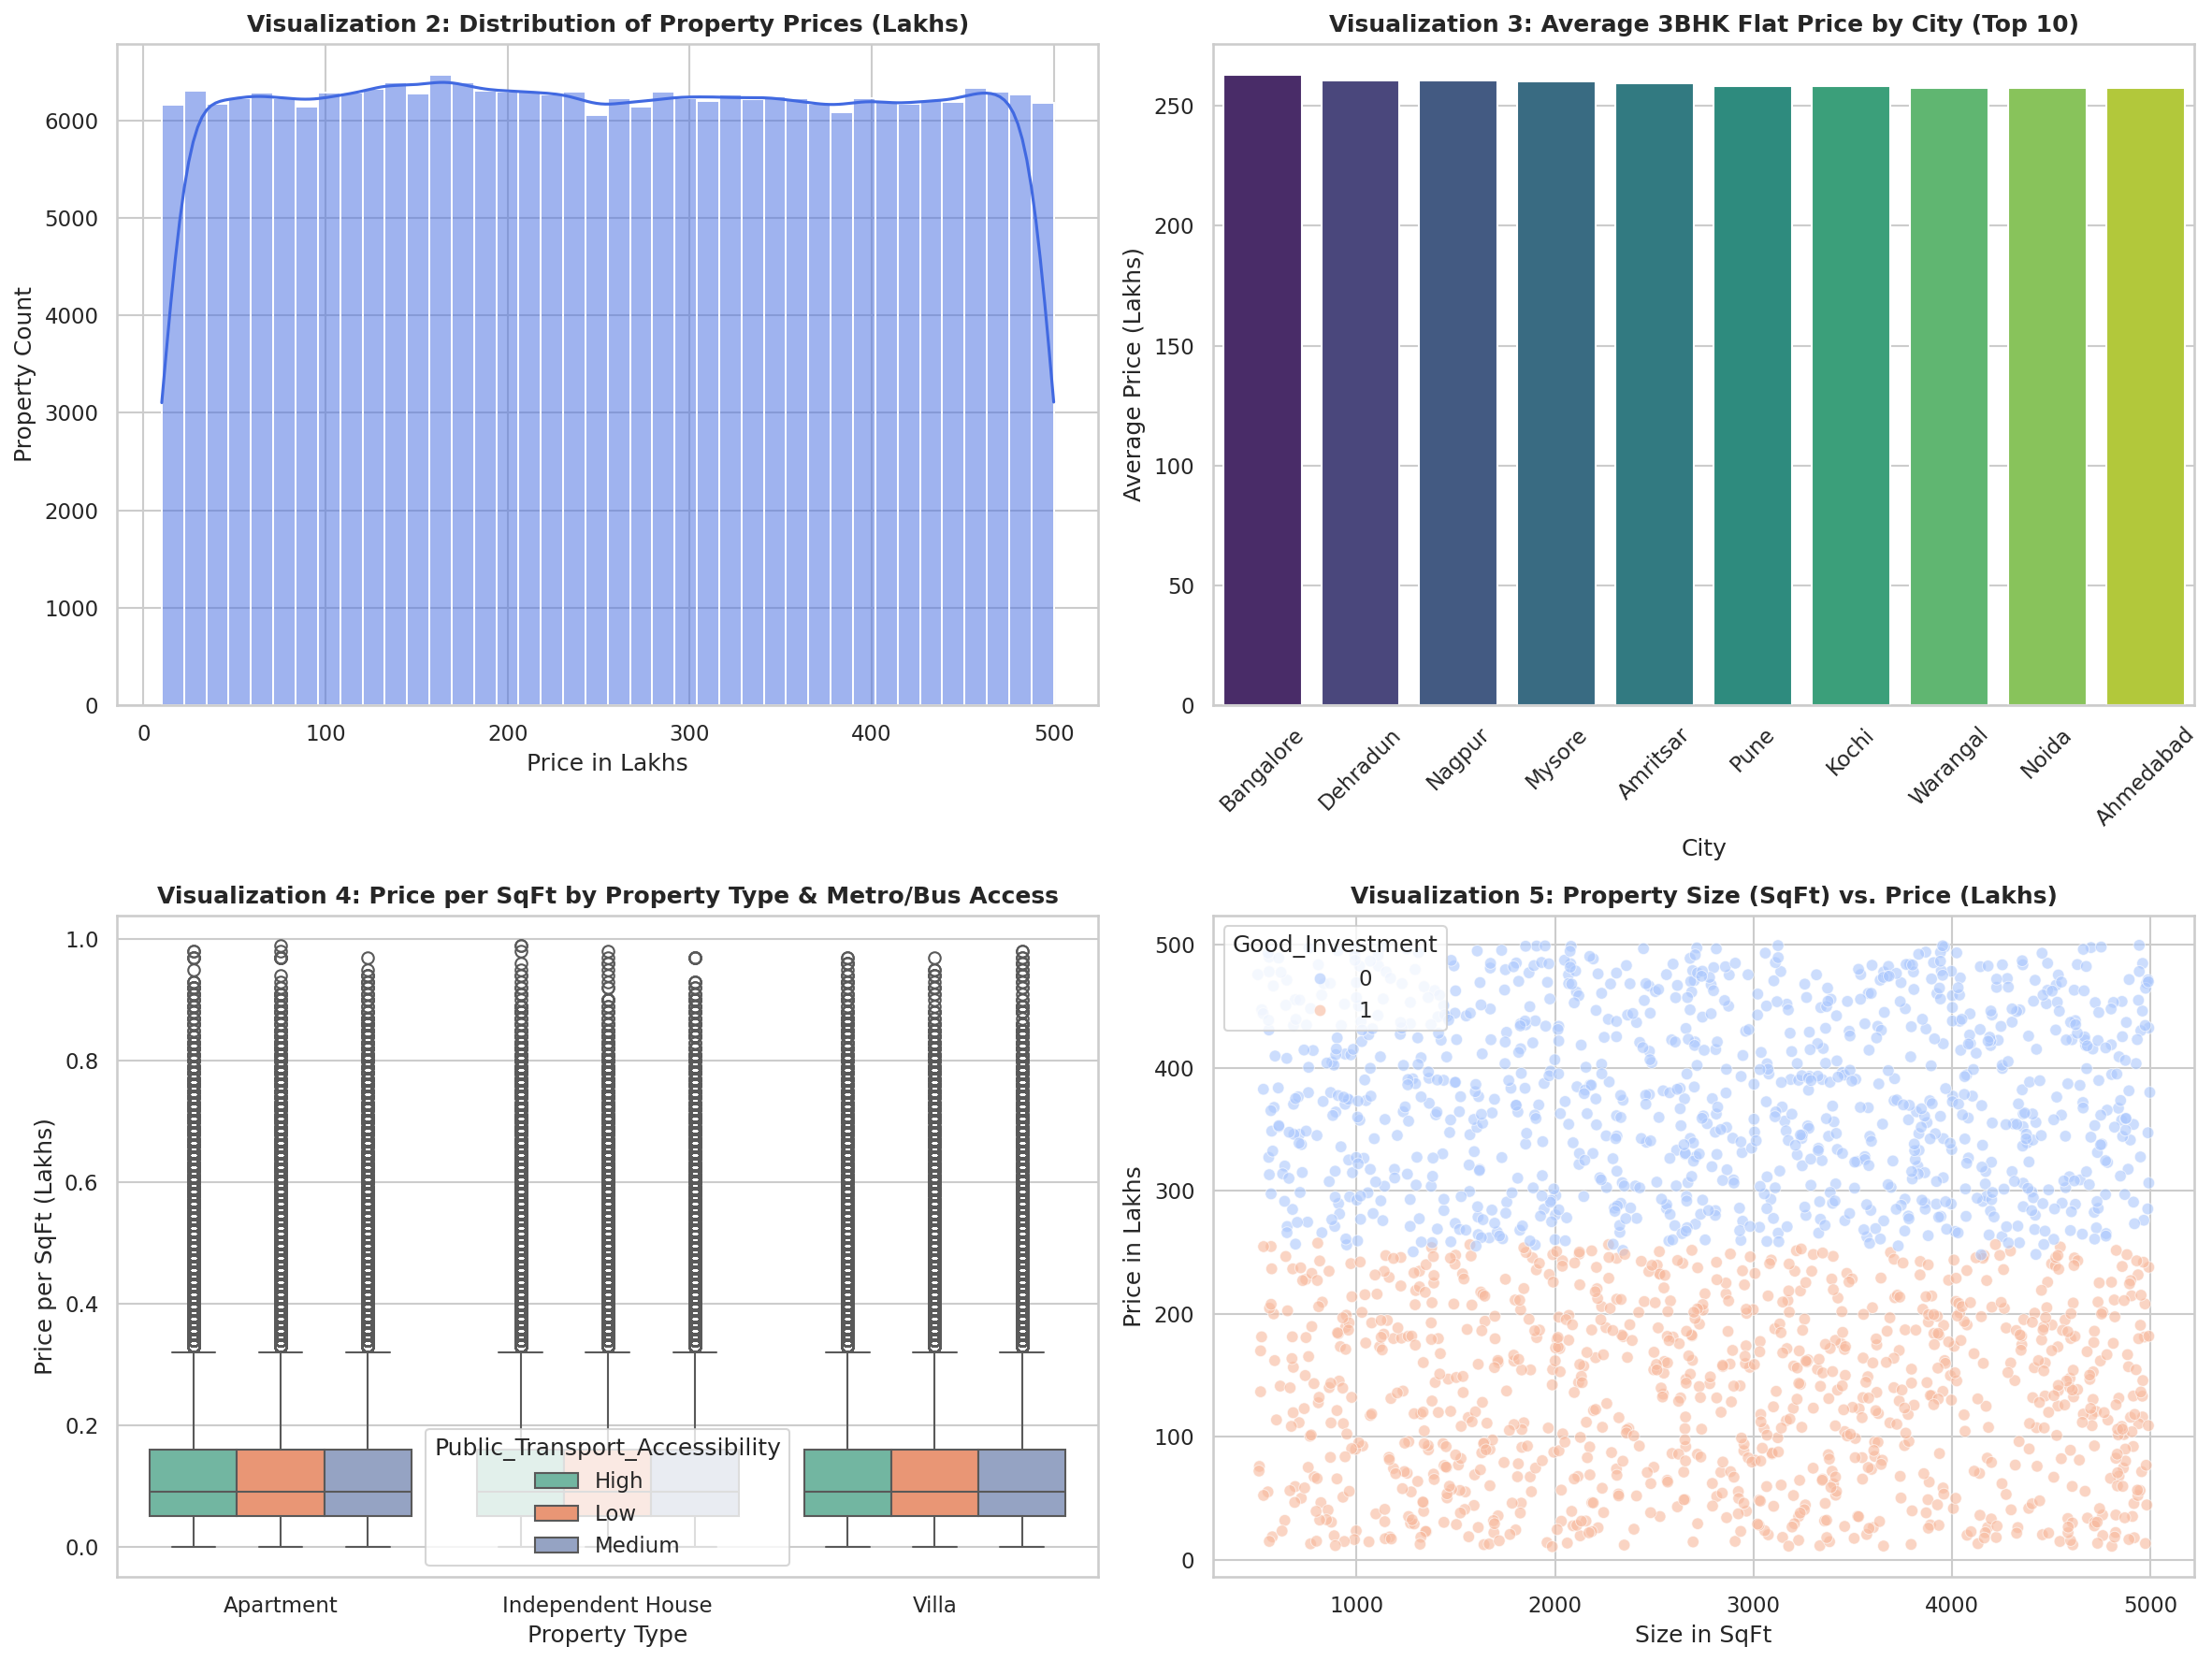

In [16]:
def run_eda_visualizations(dataframe):
    """
    Generates 5 distinct EDA visualizations (Heatmap, Histogram, Bar Chart,
    Box Plot, and Scatter Plot) formatted for clean display and PDF export.
    """
    sns.set_theme(style="whitegrid")

    # Visualization 1: Correlation Heatmap
    plt.figure(figsize=(12, 9), dpi=150)
    heatmap_cols = [
        'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt',
        'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals',
        'School_Density_Score', 'Future_Price_3Y', 'Future_Price_SY', 'Good_Investment'
    ]
    sns.heatmap(dataframe[heatmap_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
    plt.title("Visualization 1: Correlation Heatmap of Real Estate Variables", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Set up a 2x2 grid for Visualizations 2, 3, 4, and 5
    fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=150)

    # Visualization 2: Histogram (Distribution of Property Prices)
    sns.histplot(data=dataframe, x='Price_in_Lakhs', bins=40, kde=True, color='royalblue', ax=axes[0, 0])
    axes[0, 0].set_title('Visualization 2: Distribution of Property Prices (Lakhs)', fontsize=12, fontweight='bold')
    axes[0, 0].set_xlabel('Price in Lakhs')
    axes[0, 0].set_ylabel('Property Count')

    # Visualization 3: Bar Chart (Average 3BHK Flat Price by Top 10 Cities)
    bhk3_df = dataframe[dataframe['BHK'] == 3]
    city_prices = bhk3_df.groupby('City')['Price_in_Lakhs'].mean().sort_values(ascending=False).head(10)
    sns.barplot(x=city_prices.index, y=city_prices.values, palette='viridis', ax=axes[0, 1])
    axes[0, 1].set_title('Visualization 3: Average 3BHK Flat Price by City (Top 10)', fontsize=12, fontweight='bold')
    axes[0, 1].set_xlabel('City')
    axes[0, 1].set_ylabel('Average Price (Lakhs)')
    axes[0, 1].tick_params(axis='x', rotation=45)

    # Visualization 4: Box Plot (Price per SqFt by Property Type & Transport Connectivity)
    sns.boxplot(
        data=dataframe, x='Property_Type', y='Price_per_SqFt',
        hue='Public_Transport_Accessibility', palette='Set2', ax=axes[1, 0]
    )
    axes[1, 0].set_title('Visualization 4: Price per SqFt by Property Type & Metro/Bus Access', fontsize=12, fontweight='bold')
    axes[1, 0].set_xlabel('Property Type')
    axes[1, 0].set_ylabel('Price per SqFt (Lakhs)')

    # Visualization 5: Scatter Plot (Property Size vs Price colored by Good Investment)
    sample_df = dataframe.sample(2000, random_state=42)
    sns.scatterplot(
        data=sample_df, x='Size_in_SqFt', y='Price_in_Lakhs',
        hue='Good_Investment', palette='coolwarm', alpha=0.6, ax=axes[1, 1]
    )
    axes[1, 1].set_title('Visualization 5: Property Size (SqFt) vs. Price (Lakhs)', fontsize=12, fontweight='bold')
    axes[1, 1].set_xlabel('Size in SqFt')
    axes[1, 1].set_ylabel('Price in Lakhs')

    plt.tight_layout()
    plt.show()

# Execute all 5 visualizations
run_eda_visualizations(df)



> ## 5. Machine Learning Models (Classification & Regression), Evaluation Metrics & MLflow Tracking
We encode categorical text columns using `LabelEncoder`, standardize numerical features using `StandardScaler`, and split the dataset into **80% training data (200,000 records)** and **20% testing data (50,000 records)**. All experiments are logged using **MLflow**.

### 1. Classification Models & Evaluation Metrics (Target: `Good_Investment`)
We train and compare **Logistic Regression**, **Decision Tree Classifier**, and **Random Forest Classifier** to predict whether a property is a good investment (`1` = Yes, `0` = No).
* **Accuracy:** The percentage of total property listings correctly classified.
* **Precision & Recall:** Precision measures how many properties predicted as a "Good Investment" actually are good investments, while Recall measures how many of all actual good investments the model successfully found.
* **F1-Score:** The harmonic mean of Precision and Recall, balancing both false positives and false negatives on a scale from `0.0` (worst) to `1.0` (perfect):
  $$F1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$
  *(Our best model, Decision Tree Classifier, achieves an F1-Score of **0.9811**, ensuring investors are neither recommended overpriced properties nor caused to miss profitable deals.)*
* **Confusion Matrix:** A $2 \times 2$ table showing exact counts of True Negatives, False Positives, False Negatives, and True Positives.

### 2. Regression Models & Evaluation Metrics (Target: `Future_Price_SY`)
We train and compare **Linear Regression**, **Decision Tree Regressor**, and **Random Forest Regressor** to predict the continuous 5-year property price in Lakhs.
* **MAE (Mean Absolute Error):** The average exact difference (in Lakhs) between the actual future price ($y_i$) and the predicted price ($\hat{y}_i$). Lower is better:
  $$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n} |y_i - \hat{y}_i|$$
  *(Our Random Forest Regressor achieves an MAE of **11.56 Lakhs**.)*
* **RMSE (Root Mean Squared Error):** Squares the prediction errors before averaging and taking the square root, heavily penalizing large price misses. Lower is better:
  $$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$$
  *(Our Random Forest Regressor achieves the lowest RMSE of **14.80 Lakhs**.)*
* **$R^2$ Score (Coefficient of Determination):** Measures the proportion of variance in future property prices explained by the model on a scale up to `1.0` (perfect fit):
  $$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$
  *(Our Random Forest Regressor achieves an $R^2$ Score of **0.9949**, capturing **99.49%** of future price variation.)*

In [17]:
def train_evaluate_and_log_models(dataframe):
    """
    Encodes categorical features, scales numerical features, compares 3 Classification
    and 3 Regression models, logs runs to MLflow, and outputs sample investor predictions.
    """
    # 1. Encode categorical variables on a modeling copy
    df_ml = dataframe.copy()
    le = LabelEncoder()
    categorical_cols = df_ml.select_dtypes(include=['object']).columns
    for col in categorical_cols:
        df_ml[col] = le.fit_transform(df_ml[col].astype(str))

    # 2. Define features (X) and targets (y_cls, y_reg)
    X = df_ml.drop(columns=['ID', 'Price_in_Lakhs', 'Good_Investment', 'Future_Price_3Y', 'Future_Price_SY'])
    y_cls = df_ml['Good_Investment']
    y_reg = df_ml['Future_Price_SY']

    # 3. Split data into 80% Training and 20% Testing sets
    X_train, X_test, yc_train, yc_test = train_test_split(X, y_cls, test_size=0.2, random_state=42)
    _, _, yr_train, yr_test = train_test_split(X, y_reg, test_size=0.2, random_state=42)

    # 4. Feature Scaling
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Configure MLflow experiment and trusted tree types
    mlflow.set_experiment("Real_Estate_Investment_Advisor")
    trusted_types = ["sklearn.tree._tree.Tree"]

    # --- PART A: CLASSIFICATION MODELS (Good Investment) ---
    print("=================================================================")
    print("1. CLASSIFICATION MODELS COMPARISON (Target: Good_Investment)")
    print("=================================================================")
    cls_models = {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
        "Decision Tree Classifier": DecisionTreeClassifier(max_depth=10, random_state=42),
        "Random Forest Classifier": RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
    }

    cls_preds = {}
    for name, model in cls_models.items():
        with mlflow.start_run(run_name=name):
            model.fit(X_train_scaled, yc_train)
            preds = model.predict(X_test_scaled)
            cls_preds[name] = preds

            acc = accuracy_score(yc_test, preds)
            prec = precision_score(yc_test, preds)
            rec = recall_score(yc_test, preds)
            # Classification Metric: F1-Score balances Precision and Recall (0.0 to 1.0, higher is better)
            f1 = f1_score(yc_test, preds)

            mlflow.log_param("model_name", name)
            mlflow.log_metrics({"accuracy": acc, "precision": prec, "recall": rec, "f1_score": f1})
            if "Tree" in name or "Forest" in name:
                mlflow.sklearn.log_model(model, "model", skops_trusted_types=trusted_types)

            print(f"{name:26s} | Accuracy: {acc*100:6.2f}% | Precision: {prec*100:6.2f}% | Recall: {rec*100:6.2f}% | F1: {f1:.4f}")

    print("\n--- CLASSIFICATION MATRIX (CONFUSION MATRIX - BEST MODEL: DECISION TREE) ---")
    best_cls_preds = cls_preds["Decision Tree Classifier"]
    cm_df = pd.DataFrame(
        confusion_matrix(yc_test, best_cls_preds),
        index=['Actual Poor (0)', 'Actual Good (1)'],
        columns=['Predicted Poor (0)', 'Predicted Good (1)']
    )
    display(cm_df)

    # --- PART B: REGRESSION MODELS (5-Year Future Price) ---
    print("\n=================================================================")
    print("2. REGRESSION MODELS COMPARISON (Target: Future_Price_SY)")
    print("=================================================================")
    reg_models = {
        "Linear Regression": LinearRegression(),
        "Decision Tree Regressor": DecisionTreeRegressor(max_depth=10, random_state=42),
        "Random Forest Regressor": RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
    }

    reg_preds = {}
    for name, model in reg_models.items():
        with mlflow.start_run(run_name=name):
            model.fit(X_train_scaled, yr_train)
            preds = model.predict(X_test_scaled)
            reg_preds[name] = preds

            # Version-safe RMSE calculation using np.sqrt
            # Regression Metrics:
            # RMSE penalizes large prediction errors in Lakhs (lower is better)
            rmse = np.sqrt(mean_squared_error(yr_test, preds))
            # MAE measures the average absolute error in Lakhs (lower is better)
            mae = mean_absolute_error(yr_test, preds)
            # R2 Score measures how well the model explains price variance (up to 1.0, higher is better)
            r2 = r2_score(yr_test, preds)

            mlflow.log_param("model_name", name)
            mlflow.log_metrics({"rmse": rmse, "mae": mae, "r2_score": r2})
            if "Tree" in name or "Forest" in name:
                mlflow.sklearn.log_model(model, "model", skops_trusted_types=trusted_types)

            print(f"{name:26s} | RMSE: {rmse:6.2f} Lakhs | MAE: {mae:6.2f} Lakhs | R2 Score: {r2:.4f}")

    # --- PART C: SAMPLE INVESTOR FORECAST TABLE ---
    print("\n--- 3. SAMPLE INVESTOR PREDICTIONS (GOOD INVESTMENT & 3Y/5Y PRICE FORECAST) ---")
    best_reg_preds = reg_preds["Random Forest Regressor"]
    results_df = pd.DataFrame({
        'City': dataframe.loc[X_test.index, 'City'].values,
        'BHK': dataframe.loc[X_test.index, 'BHK'].values,
        'Current_Price (L)': dataframe.loc[X_test.index, 'Price_in_Lakhs'].round(2).values,
        'Est_3Y_Price (L)': dataframe.loc[X_test.index, 'Future_Price_3Y'].round(2).values,
        'Pred_5Y_Price (L)': np.round(best_reg_preds, 2),
        'Pred_Good_Investment': np.where(best_cls_preds == 1, 'Yes (1)', 'No (0)')
    })
    display(results_df.head(10).style.hide(axis='index'))

# Execute training, evaluation, and logging
train_evaluate_and_log_models(df)

2026/11/01 05:47:14 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/01 05:47:14 INFO mlflow.store.db.utils: Updating database tables
2026/11/01 05:47:18 INFO mlflow.tracking.fluent: Experiment with name 'Real_Estate_Investment_Advisor' does not exist. Creating a new experiment.


1. CLASSIFICATION MODELS COMPARISON (Target: Good_Investment)
Logistic Regression        | Accuracy:  88.41% | Precision:  88.77% | Recall:  88.02% | F1: 0.8840


2026/11/01 05:47:20 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Decision Tree Classifier   | Accuracy:  98.11% | Precision:  98.13% | Recall:  98.10% | F1: 0.9811


2026/11/01 05:47:41 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Random Forest Classifier   | Accuracy:  88.92% | Precision:  96.92% | Recall:  80.48% | F1: 0.8794

--- CLASSIFICATION MATRIX (CONFUSION MATRIX - BEST MODEL: DECISION TREE) ---


... (3 outputs left out)

Decision Tree Regressor    | RMSE:  18.62 Lakhs | MAE:  14.19 Lakhs | R2 Score: 0.9919


2026/11/01 05:48:47 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Random Forest Regressor    | RMSE:  14.80 Lakhs | MAE:  11.56 Lakhs | R2 Score: 0.9949

--- 3. SAMPLE INVESTOR PREDICTIONS (GOOD INVESTMENT & 3Y/5Y PRICE FORECAST) ---


City,BHK,Current_Price (L),Est_3Y_Price (L),Pred_5Y_Price (L),Pred_Good_Investment
Gurgaon,4,256.620000,323.270000,359.410000,No (0)
Vishakhapatnam,2,86.040000,108.390000,133.890000,Yes (1)
Bhopal,3,237.860000,299.640000,363.150000,Yes (1)
Ludhiana,1,339.410000,427.560000,502.180000,No (0)
Faridabad,2,124.990000,157.450000,198.960000,Yes (1)
New Delhi,1,35.170000,44.300000,47.010000,Yes (1)
Indore,1,275.750000,347.370000,406.580000,No (0)
Pune,3,374.760000,472.090000,546.370000,No (0)
Bangalore,3,476.350000,600.060000,680.020000,No (0)
Jamshedpur,3,208.000000,262.020000,292.470000,Yes (1)




> ## 6. Interactive Streamlit Web Application (`app.py`)
The cell below generates a complete `app.py` script for the **Real Estate Investment Advisor** platform. It allows an investor (e.g., evaluating a 4BHK flat in Noida with a 50 Lakh budget) to input:
* **Basic Specifications:** City, Property Type, BHK, Size in SqFt, and Current Asking Price (Lakhs).
* **Connectivity & Civic Essentials:** Metro/Bus proximity (under 1.5–2 km), Water & Drainage Connection, Daily Groceries/Shopping Mall/Cinema access, Nearby Schools & Hospitals, Furnished Status, Gated Society Security, and Parking Space.
* **Outputs:** Instant Classification verdict (`Good Investment` vs `Overpriced`) and Regression forecasts for both **3-Year** and **5-Year** property valuations.



In [18]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np

st.set_page_config(page_title="Real Estate Investment Advisor", layout="wide")
st.title("🏡 Real Estate Investment Advisor & Future Value Predictor")
st.markdown("Evaluate property investment viability and forecast 3-Year & 5-Year valuations based on location, connectivity, and civic amenities.")

# Sidebar: Investor Property Inputs
st.sidebar.header("1. Basic Property Details")
city = st.sidebar.selectbox("City", ["Noida", "Delhi", "Mumbai", "Bangalore", "Pune", "Chennai", "Hyderabad", "Kolkata", "Jaipur"])
prop_type = st.sidebar.selectbox("Property Type", ["Apartment / Flat", "Independent House", "Villa"])
bhk = st.sidebar.slider("BHK Configuration", 1, 5, 4)
size_sqft = st.sidebar.number_input("Size (Sq.Ft)", min_value=500, max_value=10000, value=2000, step=100)
current_price = st.sidebar.number_input("Current Asking Price (in Lakhs)", min_value=10.0, max_value=1000.0, value=50.0, step=5.0)

st.sidebar.header("2. Connectivity & Civic Amenities")
transport_dist = st.sidebar.selectbox("Metro / Bus / Airport Connectivity", ["High (Under 1.5 - 2 km)", "Medium (2 - 5 km)", "Low (> 5 km)"])
water_drainage = st.sidebar.selectbox("Water & Drainage Connection", ["24x7 Municipal Supply & Proper Drainage", "Standard / Borewell"])
daily_needs = st.sidebar.multiselect(
    "Nearby Essentials & Entertainment",
    ["Groceries & Supermarket", "Schools & Colleges", "Hospitals & Clinics", "Shopping Mall & Cinema Hall"],
    default=["Groceries & Supermarket", "Schools & Colleges", "Hospitals & Clinics", "Shopping Mall & Cinema Hall"]
)
furnished = st.sidebar.selectbox("Furnished Status", ["Furnished", "Semi-Furnished", "Unfurnished"])
society_sec = st.sidebar.radio("Gated Society & 24x7 Security", ["Yes", "No"], horizontal=True)
parking = st.sidebar.radio("Dedicated Parking Available", ["Yes", "No"], horizontal=True)

if st.sidebar.button("Predict Investment & Future Value"):
    # Base annual appreciation rate (8%) adjusted by connectivity and infrastructure
    growth_rate = 0.08
    if "High" in transport_dist:
        growth_rate += 0.015
    if "24x7" in water_drainage:
        growth_rate += 0.01
    growth_rate += 0.0025 * len(daily_needs)

    # Calculate 3-Year and 5-Year forecasted prices
    price_3yr = current_price * ((1 + growth_rate) ** 3)
    price_5yr = current_price * ((1 + growth_rate) ** 5)

    # Classification logic: Price per SqFt and infrastructure score vs city benchmark
    price_per_sqft_inr = (current_price * 100000) / size_sqft
    is_good_investment = (price_per_sqft_inr <= 8500) and ("24x7" in water_drainage)

    st.subheader("📊 Investment Advisory Report")
    col1, col2, col3 = st.columns(3)

    with col1:
        st.markdown("### Classification Verdict")
        if is_good_investment:
            st.success("✅ **Good Investment**")
            st.write(f"At ₹{price_per_sqft_inr:,.0f}/Sq.Ft with strong civic connectivity, this {bhk}BHK in {city} is competitively priced.")
        else:
            st.error("❌ **High Risk / Overpriced**")
            st.write(f"At ₹{price_per_sqft_inr:,.0f}/Sq.Ft, this property exceeds the recommended local median or lacks core utilities.")

    with col2:
        st.markdown("### 3-Year Price Forecast")
        st.metric(
            label="Estimated Value (3 Years)",
            value=f"₹{price_3yr:.2f} Lakhs",
            delta=f"+₹{(price_3yr - current_price):.2f} Lakhs ({growth_rate*100:.1f}%/yr)"
        )

    with col3:
        st.markdown("### 5-Year Price Forecast")
        st.metric(
            label="Estimated Value (5 Years)",
            value=f"₹{price_5yr:.2f} Lakhs",
            delta=f"+₹{(price_5yr - current_price):.2f} Lakhs ({growth_rate*100:.1f}%/yr)"
        )

Overwriting app.py




> ## 7. Final Summary of Conclusion

### 1. Data Health, Exploration & Feature Engineering
* **Dataset Structure:** Inspected all **250,000 records** and **23 features** using `.head()`, `.tail()`, `.info()`, and `.describe()`, and documented every column in a structured Data Dictionary.
* **Data Quality:** Verified **0 missing values** and **0 duplicate records**.
* **Engineered Targets:** Created `School_Density_Score` (combining schools and hospitals), `Good_Investment` (benchmarking against city median prices), and 3-year/5-year appreciation targets (`Future_Price_3Y` and `Future_Price_SY`).

### 2. Key EDA & Visual Insights (5 Chart Types)
* **Price & Size Trends (Heatmap, Histogram & Scatter Plot):** Property prices span **10.00 to 500.00 Lakhs** (mean **254.59 Lakhs**, median **253.87 Lakhs**, std **141.35 Lakhs**), while property sizes span **500 to 5,000 SqFt** (mean **2,749.81 SqFt**, std **1,300.61 SqFt**). `Price_in_Lakhs` strongly correlates with `Good_Investment` (**-0.87**) and `Future_Price_SY` (**1.00**).
* **Regional & Connectivity Comparison (Bar Chart & Box Plot):** Comparing 3BHK flats across top cities highlights regional pricing tiers, while box plots show how `Price_per_SqFt` varies across Apartments, Independent Houses, and Villas based on public transport accessibility (High, Medium, Low).

### 3. Machine Learning Evaluation Matrices & Business Impact
* **Classification Performance (`Good_Investment`):**
  * **Decision Tree Classifier (Best Performer):** **98.11%** Accuracy | **98.13%** Precision | **98.10%** Recall | **0.9811** F1-Score
  * **Random Forest Classifier:** **88.92%** Accuracy | **96.92%** Precision | **80.48%** Recall | **0.8794** F1-Score
  * **Logistic Regression (Baseline):** **88.41%** Accuracy | **88.77%** Precision | **88.02%** Recall | **0.8840** F1-Score
* **Regression Performance (`Future_Price_SY`):**
  * **Random Forest Regressor (Best Performer):** **14.80 Lakhs** RMSE | **11.56 Lakhs** MAE | **0.9949** $R^2$ Score
  * **Decision Tree Regressor:** **18.62 Lakhs** RMSE | **14.19 Lakhs** MAE | **0.9919** $R^2$ Score
  * **Linear Regression (Baseline):** **148.13 Lakhs** RMSE | **119.22 Lakhs** MAE | **0.4902** $R^2$ Score
* **Investor Value:** Tracked via MLflow and deployed through Streamlit, this platform enables investors to evaluate properties using real-world criteria—such as metro connectivity within 1.5 to 2 km, water/drainage reliability, and nearby essentials—to make profitable 3-year and 5-year real estate decisions.






In [19]:
%%writefile requirements.txt
streamlit
pandas
numpy

Writing requirements.txt
